# 01 · EDA y preparación — Dato e Información

**Fuente:** `data/raw/registros_sinteticos.csv`. Estos datos son **simulados** con `src/generate_data.py`. Sirven para construir y probar el pipeline. No permiten afirmar qué tan preciso sería el modelo con estudiantes reales.

Cada fila es un registro **estudiante × asignatura × semestre** (el **dato**). En este notebook se revisa la calidad de los datos, se describe la **información** que se deriva de ellos y se prepara la partición train/test por estudiante.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from features import RAIZ, NUM, CAT, OBJETIVO, GRUPO, particion_por_estudiante

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
df = pd.read_csv(RAIZ / "data/raw/registros_sinteticos.csv")
print(df.shape)
df.head()

(6000, 22)


,id_estudiante,semestre,asignatura,creditos,dificultad_asignatura,jornada,trabaja,asignaturas_reprobadas_previas,horas_estudio_semana,asistencia_pct,...,ejercicios_correctos_pct,comprension_tema,nota_corte1,nota_corte2,horas_sueno,dias_a_proxima_evaluacion,nota_final,promedio_cortes,tendencia_notas,riesgo_academico
0,1,1,Calculo Diferencial,4,5,diurna,0,0,NaN,76.0,...,52.5,3.0,4.07,2.95,5.3,25,3.60,3.51,-1.12,0
1,1,1,Bases de Datos,3,3,diurna,0,0,5.3,81.3,...,59.9,4.0,3.58,3.94,7.0,25,3.90,3.76,0.36,0
2,1,1,Fisica Mecanica,4,5,diurna,0,0,7.5,99.9,...,38.0,2.0,3.88,3.61,5.5,17,3.23,3.74,-0.27,0
3,1,1,Ingenieria de Software,3,3,diurna,0,0,7.3,87.1,...,59.1,3.0,3.96,4.09,6.6,20,4.21,4.03,0.13,0
4,1,2,Estructuras de Datos,4,4,diurna,0,0,5.2,94.8,...,34.5,3.0,3.44,3.87,7.5,18,3.91,3.66,0.43,0


## 1. Tipos de datos

In [2]:
df.dtypes.to_frame("tipo").T

,id_estudiante,semestre,asignatura,creditos,dificultad_asignatura,jornada,trabaja,asignaturas_reprobadas_previas,horas_estudio_semana,asistencia_pct,...,ejercicios_correctos_pct,comprension_tema,nota_corte1,nota_corte2,horas_sueno,dias_a_proxima_evaluacion,nota_final,promedio_cortes,tendencia_notas,riesgo_academico
tipo,int64,int64,str,int64,int64,str,int64,int64,float64,float64,...,float64,float64,float64,float64,float64,int64,float64,float64,float64,int64


## 2. Nulos y duplicados

In [3]:
nulos = df.isna().sum()
display(pd.DataFrame({"nulos": nulos, "pct": (nulos / len(df) * 100).round(2)}).query("nulos > 0"))
print("Filas duplicadas exactas:", df.duplicated().sum())
print("Duplicados de clave (estudiante, semestre, asignatura):",
      df.duplicated([GRUPO, "semestre", "asignatura"]).sum())
print("Estudiantes:", df[GRUPO].nunique(), "| registros por estudiante (media):",
      round(df.groupby(GRUPO).size().mean(), 1))

,nulos,pct
horas_estudio_semana,171,2.85
ejercicios_correctos_pct,171,2.85
comprension_tema,186,3.10


Filas duplicadas exactas: 0
Duplicados de clave (estudiante, semestre, asignatura): 0
Estudiantes: 300 | registros por estudiante (media): 20.0


## 3. Rangos válidos y outliers
Primero se comprueba que cada variable esté en su dominio (porcentajes en 0-100, notas en 0-5, comprensión en 1-5). Después se cuentan los outliers con la regla IQR (1,5 × IQR).

In [4]:
rangos = {"asistencia_pct": (0, 100), "actividades_completadas_pct": (0, 100),
          "ejercicios_correctos_pct": (0, 100), "comprension_tema": (1, 5),
          "nota_corte1": (0, 5), "nota_corte2": (0, 5), "nota_final": (0, 5),
          "horas_estudio_semana": (0, 80), "horas_sueno": (0, 24)}
fuera = {c: int(((df[c] < a) | (df[c] > b)).sum()) for c, (a, b) in rangos.items()}
print("Valores fuera de dominio:", fuera)

cont = [c for c in NUM if df[c].nunique() > 10]
q1, q3 = df[cont].quantile(0.25), df[cont].quantile(0.75)
iqr = q3 - q1
out = ((df[cont] < q1 - 1.5 * iqr) | (df[cont] > q3 + 1.5 * iqr)).sum()
display(out.to_frame("outliers_IQR").assign(pct=lambda t: (t.outliers_IQR / len(df) * 100).round(2)).T)

Valores fuera de dominio: {'asistencia_pct': 0, 'actividades_completadas_pct': 0, 'ejercicios_correctos_pct': 0, 'comprension_tema': 0, 'nota_corte1': 0, 'nota_corte2': 0, 'nota_final': 0, 'horas_estudio_semana': 0, 'horas_sueno': 0}


,horas_estudio_semana,asistencia_pct,inasistencias,actividades_completadas_pct,ejercicios_correctos_pct,nota_corte1,nota_corte2,horas_sueno,dias_a_proxima_evaluacion,promedio_cortes,tendencia_notas
outliers_IQR,26.00,34.00,30.0,18.0,17.00,19.00,23.00,46.00,0.0,18.0,42.0
pct,0.43,0.57,0.5,0.3,0.28,0.32,0.38,0.77,0.0,0.3,0.7


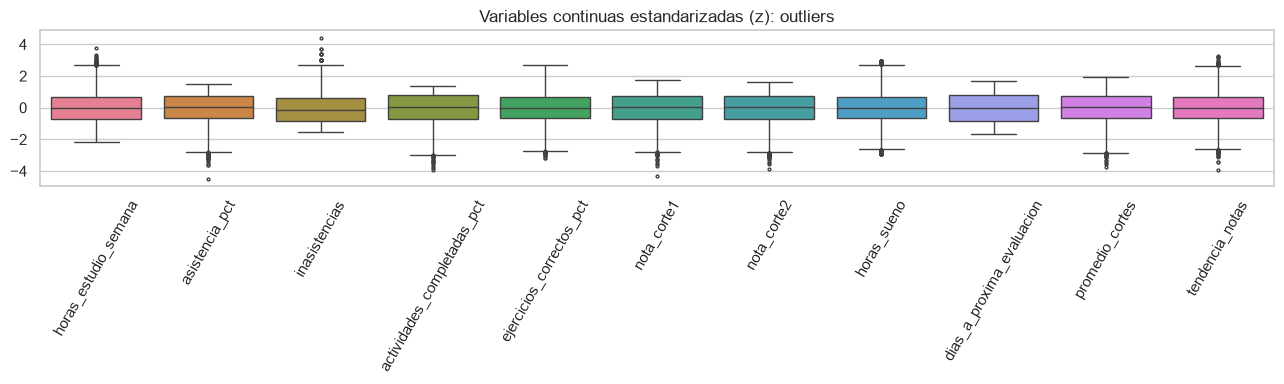

In [5]:
fig, ax = plt.subplots(figsize=(13, 4))
z = (df[cont] - df[cont].mean()) / df[cont].std()
sns.boxplot(data=z, ax=ax, fliersize=2)
ax.set_title("Variables continuas estandarizadas (z): outliers")
ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

**Decisión sobre outliers:** todos los valores están dentro de su dominio. Los outliers de IQR son casos extremos plausibles: alguien con asistencia del 50 % o una nota de corte cercana a 0 es justamente un caso de riesgo. Por eso **no se eliminan**. Random Forest y el árbol son robustos a estos valores, y para K-Means se escalan las variables.

## 4. Variable objetivo `riesgo_academico`
`riesgo_academico = 1` si `nota_final < 3.0` (escala 0-5).

{0: 4742, 1: 1258} | % riesgo = 20.97


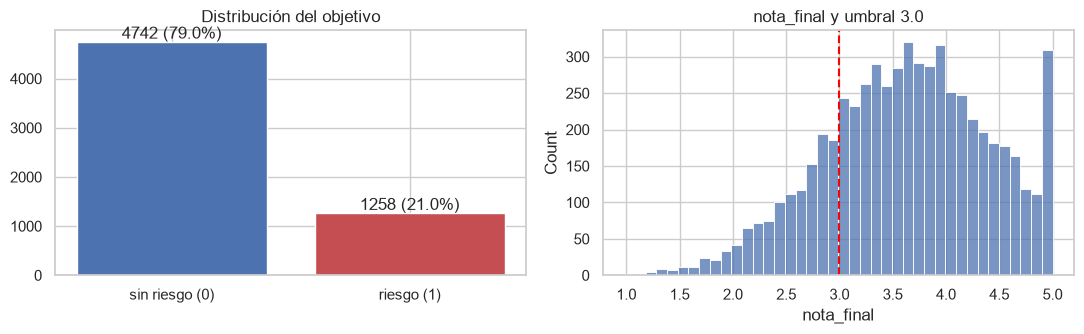

In [6]:
dist = df[OBJETIVO].value_counts().sort_index()
print(dist.to_dict(), "| % riesgo =", round(df[OBJETIVO].mean() * 100, 2))
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
axs[0].bar(["sin riesgo (0)", "riesgo (1)"], dist.values, color=["#4C72B0", "#C44E52"])
axs[0].set_title("Distribución del objetivo")
for i, v in enumerate(dist.values):
    axs[0].text(i, v, f"{v} ({v / len(df):.1%})", ha="center", va="bottom")
sns.histplot(df.nota_final, bins=40, ax=axs[1]); axs[1].axvline(3.0, color="red", ls="--")
axs[1].set_title("nota_final y umbral 3.0")
plt.tight_layout(); plt.show()

Las clases están **desbalanceadas** (~21 % de riesgo). Por eso en los modelos se usa `class_weight="balanced"` y se evalúa con recall, F1, PR-AUC y ROC-AUC de la clase riesgo, no solo con accuracy.

## 5. Correlaciones

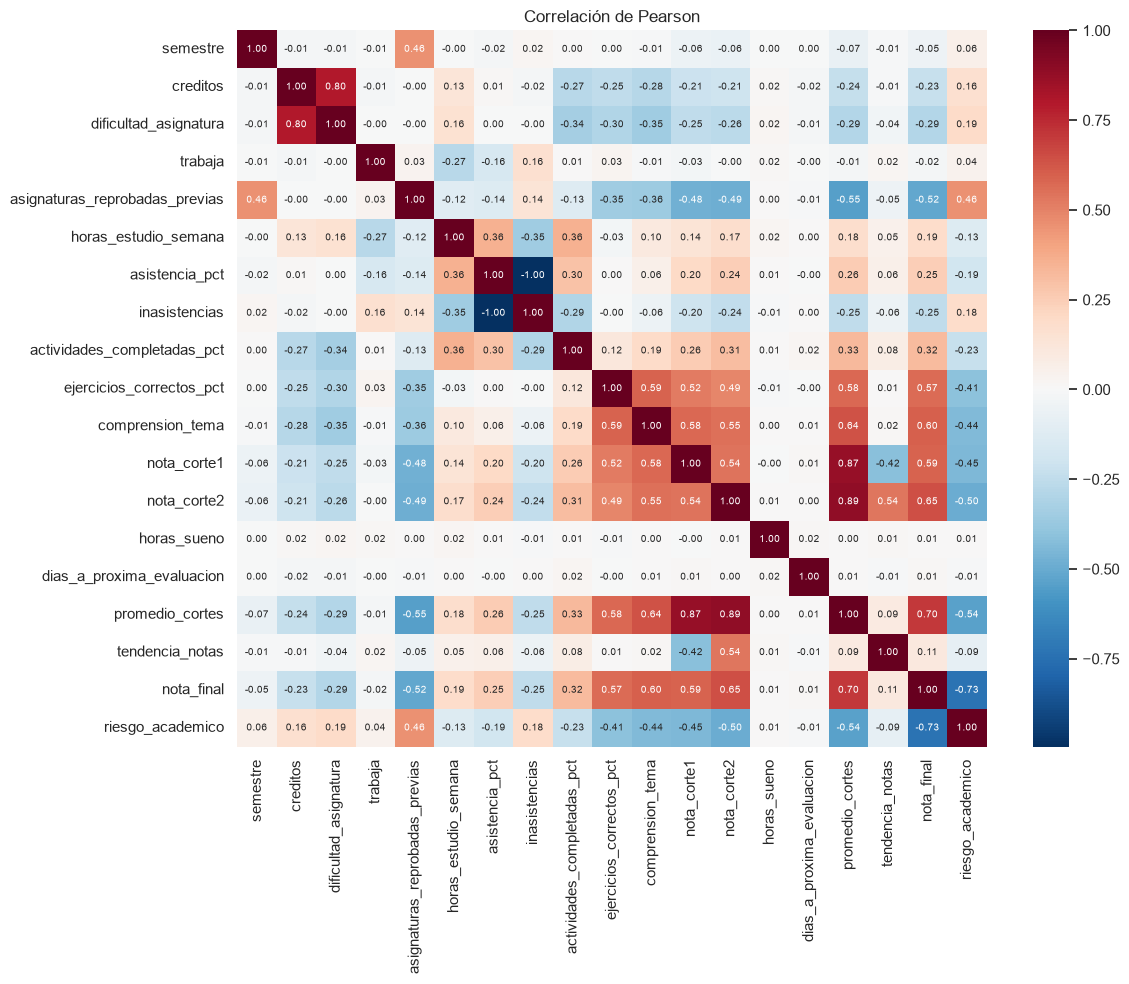

In [7]:
corr = df[NUM + ["nota_final", OBJETIVO]].corr()
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlación de Pearson"); plt.tight_layout(); plt.show()

In [8]:
display(corr[OBJETIVO].drop([OBJETIVO, "nota_final"]).sort_values().round(3).to_frame("corr_con_riesgo").T)
pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
print("Pares con |r| > 0.8 (redundancia):")
print(pares[pares.abs() > 0.8].round(3))

,promedio_cortes,nota_corte2,nota_corte1,comprension_tema,ejercicios_correctos_pct,actividades_completadas_pct,asistencia_pct,horas_estudio_semana,tendencia_notas,dias_a_proxima_evaluacion,horas_sueno,trabaja,semestre,creditos,inasistencias,dificultad_asignatura,asignaturas_reprobadas_previas
corr_con_riesgo,-0.538,-0.496,-0.447,-0.439,-0.409,-0.227,-0.185,-0.135,-0.088,-0.009,0.005,0.044,0.061,0.163,0.184,0.194,0.462


Pares con |r| > 0.8 (redundancia):
creditos        dificultad_asignatura    0.804
asistencia_pct  inasistencias           -0.995
nota_corte1     promedio_cortes          0.868
nota_corte2     promedio_cortes          0.888
dtype: float64


`nota_final` aparece aquí solo para describir los datos. **No se usa como feature**, porque es la base del objetivo y sería fuga de datos. `inasistencias` es casi una transformación lineal de `asistencia_pct`, y `promedio_cortes` se calcula a partir de los dos cortes. Son variables redundantes, pero no dañan a los modelos de árboles.

## 6. Relación de los hábitos con el riesgo

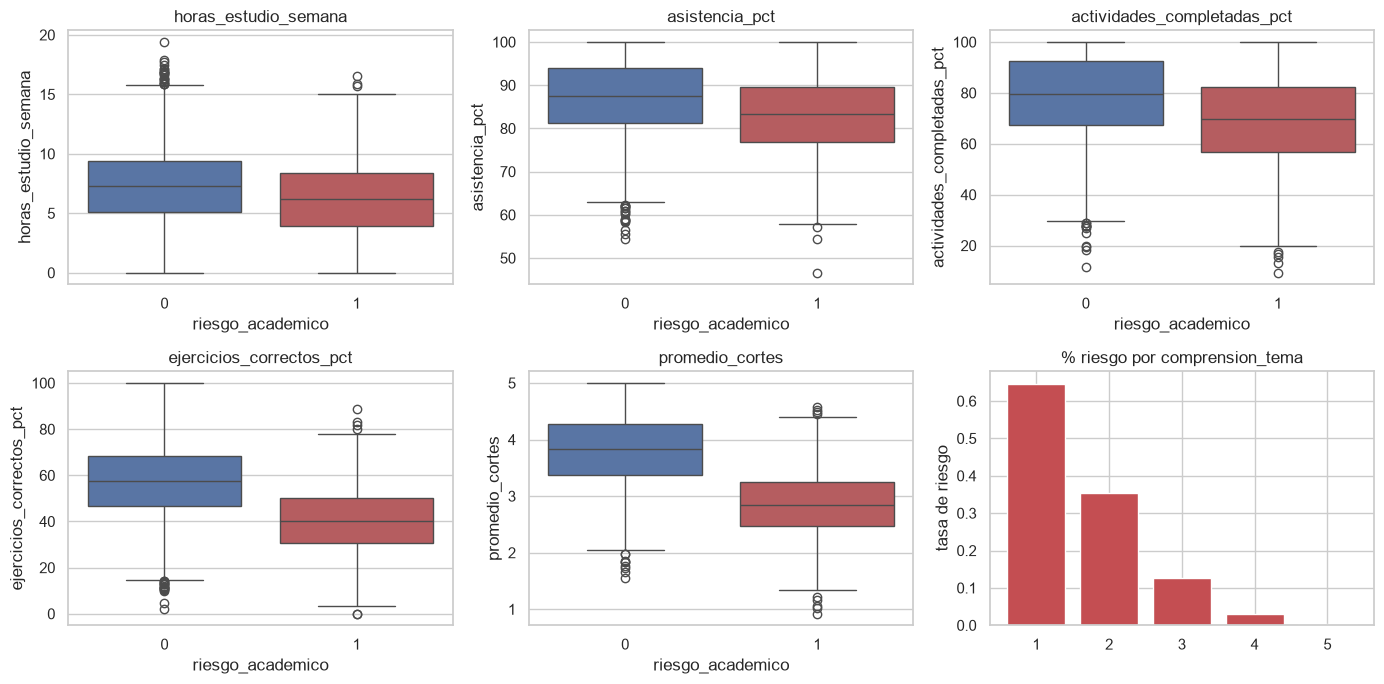

In [9]:
fig, axs = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axs.flat, ["horas_estudio_semana", "asistencia_pct", "actividades_completadas_pct",
                            "ejercicios_correctos_pct", "promedio_cortes"]):
    sns.boxplot(data=df, x=OBJETIVO, y=c, ax=ax, hue=OBJETIVO, palette=["#4C72B0", "#C44E52"], legend=False)
    ax.set_title(c)
tasa = df.groupby("comprension_tema")[OBJETIVO].mean()
axs.flat[5].bar(tasa.index.astype(int).astype(str), tasa.values, color="#C44E52")
axs.flat[5].set_title("% riesgo por comprension_tema"); axs.flat[5].set_ylabel("tasa de riesgo")
plt.tight_layout(); plt.show()

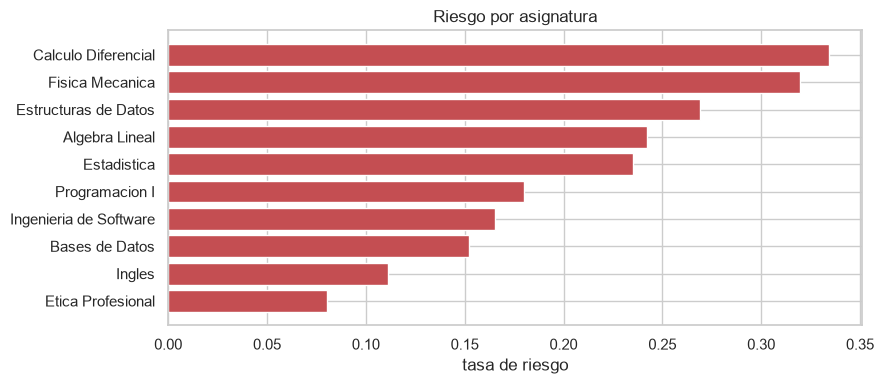

asignatura,Etica Profesional,Ingles,Bases de Datos,Ingenieria de Software,Programacion I,Estadistica,Algebra Lineal,Estructuras de Datos,Fisica Mecanica,Calculo Diferencial
dificultad,1.000,2.000,3.000,3.000,3.00,4.000,4.000,4.000,5.00,5.000
tasa_riesgo,0.081,0.111,0.152,0.165,0.18,0.235,0.242,0.269,0.32,0.334


jornada     diurna        nocturna      
trabaja          0      1        0     1
tasa_riesgo  0.183  0.249    0.237  0.21

In [10]:
por_mat = df.groupby("asignatura").agg(dificultad=("dificultad_asignatura", "first"),
                                       tasa_riesgo=(OBJETIVO, "mean")).sort_values("tasa_riesgo")
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(por_mat.index, por_mat.tasa_riesgo, color="#C44E52")
ax.set_xlabel("tasa de riesgo"); ax.set_title("Riesgo por asignatura")
plt.tight_layout(); plt.show()
display(por_mat.round(3).T)
display(df.groupby(["jornada", "trabaja"])[OBJETIVO].mean().round(3).to_frame("tasa_riesgo").T)

## 7. Del dato a la información

| Dato (registro crudo) | Información (indicador derivado) | Qué dice |
|---|---|---|
| `nota_corte1`, `nota_corte2` | `promedio_cortes` = (c1 + c2) / 2 | nivel de desempeño antes del final |
| `nota_corte1`, `nota_corte2` | `tendencia_notas` = c2 − c1 | si el estudiante mejora (+) o empeora (−) |
| actividades entregadas / asignadas | `actividades_completadas_pct` | constancia con las tareas |
| ejercicios resueltos bien / intentados | `ejercicios_correctos_pct` | dominio práctico del tema |
| autoevaluación 1-5 | `comprension_tema` | comprensión percibida del tema |
| clases asistidas / dictadas | `asistencia_pct` (e `inasistencias` = faltas sobre 32 clases) | presencia en clase |
| horas registradas por semana | `horas_estudio_semana` | esfuerzo dedicado |
| historial de materias | `asignaturas_reprobadas_previas` | rezago acumulado hasta el semestre anterior |
| asignatura | `dificultad_asignatura`, `creditos`, tasa de riesgo por asignatura | carga y exigencia de la materia |
| `nota_final` | `riesgo_academico` (nota_final < 3.0) | **objetivo** (nunca es feature) |

`horas_sueno` y `dias_a_proxima_evaluacion` son, según el diccionario de datos, variables de poco efecto (ruido). Su correlación con el riesgo, que se ve arriba, es casi 0. Se mantienen para comprobar que los modelos les dan poca importancia.

## 8. Partición por estudiante e imputación en un Pipeline
Un mismo estudiante tiene muchos registros. Si se separara al azar por fila, el modelo vería a ese estudiante en train y en test. Por eso se usa `GroupShuffleSplit` por `id_estudiante` (80/20, `random_state=42`). El imputador por mediana se **ajusta solo con train**.

In [11]:
train, test = particion_por_estudiante(df)
print(f"train: {len(train)} filas, {train[GRUPO].nunique()} estudiantes, riesgo {train[OBJETIVO].mean():.2%}")
print(f"test : {len(test)} filas, {test[GRUPO].nunique()} estudiantes, riesgo {test[OBJETIVO].mean():.2%}")
print("Estudiantes compartidos:", len(set(train[GRUPO]) & set(test[GRUPO])))

imputador = Pipeline([("mediana", SimpleImputer(strategy="median"))]).fit(train[NUM])
medianas = pd.Series(imputador.named_steps["mediana"].statistics_, index=NUM)
display(medianas[train[NUM].isna().any()].to_frame("mediana_train").T)

def imputar(d):
    d = d.copy(); d[NUM] = imputador.transform(d[NUM]); return d

tr_imp, te_imp = imputar(train), imputar(test)
print("Nulos tras imputar -> train:", int(tr_imp[NUM].isna().sum().sum()), "| test:", int(te_imp[NUM].isna().sum().sum()))

train: 4804 filas, 240 estudiantes, riesgo 20.98%
test : 1196 filas, 60 estudiantes, riesgo 20.90%
Estudiantes compartidos: 0


,horas_estudio_semana,ejercicios_correctos_pct,comprension_tema
mediana_train,7.0,53.9,3.0


Nulos tras imputar -> train: 0 | test: 0


In [12]:
out_dir = RAIZ / "data/processed"; out_dir.mkdir(parents=True, exist_ok=True)
limpio = pd.concat([train.assign(particion="train"), test.assign(particion="test")]).sort_index()
limpio.to_csv(out_dir / "registros_limpios.csv", index=False)
pd.concat([tr_imp.assign(particion="train"), te_imp.assign(particion="test")]).sort_index() \
  .to_csv(out_dir / "registros_imputados.csv", index=False)
print("Guardado:", [p.name for p in out_dir.iterdir()])

Guardado: ['registros_imputados.csv', 'registros_limpios.csv']


**Archivos generados**
- `registros_limpios.csv`: datos validados, con la columna `particion` y **los nulos conservados**. Los notebooks 02 y 03 parten de este archivo y vuelven a imputar dentro de sus propios Pipelines. Así, durante la validación cruzada la mediana se calcula solo con los folds de entrenamiento.
- `registros_imputados.csv`: el mismo archivo con los nulos imputados por la mediana de train. Es el resultado de la limpieza y sirve para inspeccionarla.